# 02 · The SmartShop simulator: is it realistic enough to trust?

SmartShop data is not public, and the truth about loss (who skipped what, and why) is never
fully known even inside a retailer. So `smartshop.simulate` adds SmartShop behaviour on top of
the **real** Complete Journey baskets:

| Real (dbt marts) | Simulated (`simulate/config.py`) |
|---|---|
| Members, stores, days, checkout times | Who adopted SmartShop and when; app or handset |
| Every basket's items, quantities, normal and Nectar prices | Shopper type (hidden): honest, careless, opportunist, deliberate, adaptive |
| | Genuine mistakes (missed and double scans) and deliberate non-scans |
| | Scan event log with times and deletions |
| | Today's random partial and full rescans, and what they found |

Every SmartShop session is Nectar-linked: Sainsbury's requires a Nectar card for both the app and
the handset. The cold-start case is therefore a **new SmartShop user**, not a non-member.

This notebook checks the simulation against published research, then measures today's random
rescans: the baseline the rest of the project must beat.

**Sources.** [ECR18] Beck (2018), *Self-Checkout in Retail: Measuring the Loss*, ECR Retail Loss
Group: 13 retailers, 140m scan-and-go transactions, 17m audits. [ECR22] Beck (2022), *Global
Study on Self-checkout in Retail*, ECR Retail Loss Group: 93 retailers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from smartshop.simulate.calibration import calibration_table, error_curve
from smartshop.simulate.config import SimConfig, TARGETS
from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, money, pct, save, set_style, subtitle
from smartshop.warehouse import connect

set_style()
con = connect()
q = lambda sql: con.sql(sql).df()
cfg = SimConfig()

truth = q('SELECT * FROM sim_truth.sessions')
members = q('SELECT * FROM sim_truth.members')
sessions = q('SELECT * FROM sim_obs.sessions')
rescans = q('SELECT * FROM sim_obs.rescans')

## 1. Who uses SmartShop

In [2]:
trips = q('SELECT COUNT(*) AS n, AVG(n_units) AS units FROM marts.fct_trip').iloc[0]
prior = q('''
SELECT basket_id, ROW_NUMBER() OVER (PARTITION BY member_id ORDER BY day, checkout_minute) - 1 AS prior_smartshop
FROM sim_obs.sessions
''')
pd.Series({
    'SmartShop sessions': len(sessions),
    'share of all trips': len(sessions) / trips.n,
    'median units, SmartShop sessions': truth.gt_true_units.median(),
    'members who used SmartShop': sessions.member_id.nunique(),
    'app share of sessions': (sessions.channel == 'app').mean(),
    'sessions by users with <5 earlier SmartShop sessions': (prior.prior_smartshop < 5).mean(),
}).round(3)

SmartShop sessions                                      91363.000
share of all trips                                          0.396
median units, SmartShop sessions                           12.000
members who used SmartShop                               2462.000
app share of sessions                                       0.572
sessions by users with <5 earlier SmartShop sessions        0.128
dtype: float64

## 2. Calibration against published figures

The free parameters (mistake rates, shopper mix, theft intensity) were tuned so the simulation
reproduces what [ECR18] measured in ~20,000 random full rescans and what retailers report about
how much loss is malicious [ECR22].

In [3]:
cal = calibration_table(truth, rescans)
cal

,simulated,published
check,,
"P(error), ~20 units",0.309596,0.3
"P(error), ~50 units",0.645835,0.6
"P(error), ~100 units",0.883385,0.9
Non-scans as share of item errors,0.760125,0.77
Deliberate share of non-scanned value,0.553829,"(0.46, 0.56)"
"Net loss, share of sales",0.020439,"(0.0096, 0.0468)"
Rescan rate,0.121242,0.12
Partial rescans finding an error,0.030078,0.0288
Full rescans finding an error,0.253878,None


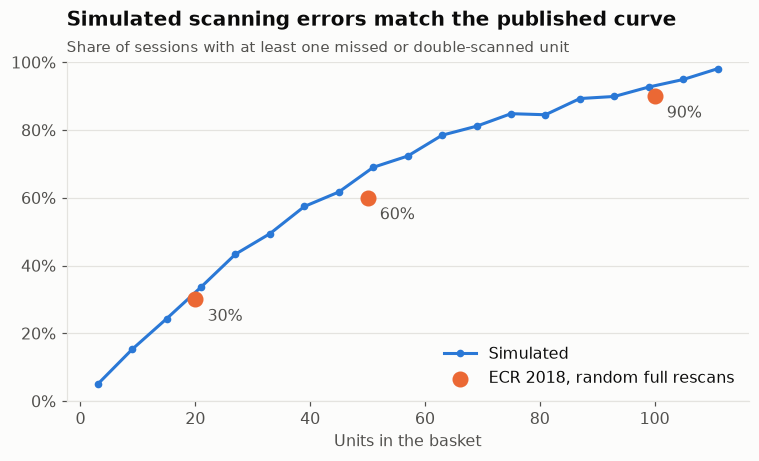

In [4]:
bins = np.arange(0, 132, 6)
truth['size_bin'] = pd.cut(truth.gt_true_units, bins)
curve = truth.groupby('size_bin', observed=True).agg(p=('gt_has_error', 'mean'), n=('gt_has_error', 'size'))
curve = curve[curve.n >= 100]
mid = [b.mid for b in curve.index]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mid, curve.p, color=BLUE, marker='o', ms=4, label='Simulated')
ecr = pd.Series({20: TARGETS['error_prob_20_items'], 50: TARGETS['error_prob_50_items'],
                 100: TARGETS['error_prob_100_items']})
ax.scatter(ecr.index, ecr.values, s=90, color=ORANGE, zorder=3, label='ECR 2018, random full rescans')
for x, y in ecr.items():
    ax.annotate(f'{y:.0%}', (x, y), textcoords='offset points', xytext=(8, -14), color=TEXT_2)
ax.yaxis.set_major_formatter(pct())
ax.set_ylim(0, 1)
ax.set_xlabel('Units in the basket')
ax.set_title('Simulated scanning errors match the published curve')
subtitle(ax, 'Share of sessions with at least one missed or double-scanned unit')
ax.legend(loc='lower right')
save(fig, '07_error_curve_calibration')
fig

## 3. Who causes the loss

Shopper types are hidden from every model. A small minority of members does most of the
deliberate non-scanning, but genuine mistakes by the honest majority still add up to a large
share of the loss.

In [5]:
by_type = (
    truth.merge(members[['member_id', 'gt_type']], on='member_id')
    .groupby('gt_type')
    .agg(sessions=('basket_id', 'size'), intent_rate=('gt_intent', 'mean'),
         net_loss=('gt_net_loss', 'sum'), deliberate=('gt_deliberate_value', 'sum'),
         accidental=('gt_accidental_value', 'sum'))
)
by_type['members'] = members.gt_type.value_counts()
by_type['share_members'] = by_type.members / by_type.members.sum()
by_type['share_sessions'] = by_type.sessions / by_type.sessions.sum()
by_type['share_loss'] = by_type.net_loss / by_type.net_loss.sum()
order = ['honest', 'careless', 'opportunist', 'deliberate', 'adaptive']
by_type = by_type.loc[order]
by_type[['share_members', 'share_sessions', 'intent_rate', 'share_loss']].round(3)

,share_members,share_sessions,intent_rate,share_loss
gt_type,,,,
honest,0.711,0.712,0.000,0.146
careless,0.148,0.150,0.000,0.102
opportunist,0.079,0.075,0.178,0.134
deliberate,0.037,0.037,0.544,0.333
adaptive,0.024,0.025,0.651,0.285


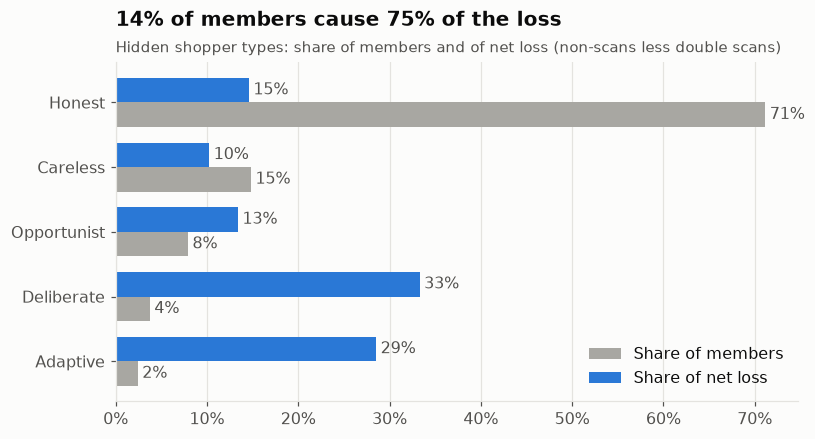

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(by_type))
h = 0.38
b1 = ax.barh(y + h / 2, by_type.share_members, h, color=GREY, label='Share of members')
b2 = ax.barh(y - h / 2, by_type.share_loss, h, color=BLUE, label='Share of net loss')
ax.bar_label(b2, labels=[f'{v:.0%}' for v in by_type.share_loss], padding=3, color=TEXT_2)
ax.bar_label(b1, labels=[f'{v:.0%}' for v in by_type.share_members], padding=3, color=TEXT_2)
ax.set_yticks(y, [t.capitalize() for t in by_type.index])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct())
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
few = by_type.loc[['opportunist', 'deliberate', 'adaptive']]
ax.set_title(f'{few.share_members.sum():.0%} of members cause {few.share_loss.sum():.0%} of the loss')
subtitle(ax, 'Hidden shopper types: share of members and of net loss (non-scans less double scans)')
ax.legend(loc='lower right')
save(fig, '08_loss_by_shopper_type')
fig

## 4. Where deliberate loss sits: high-risk, high-value items

In [7]:
units = q('''
SELECT is_high_risk,
       SUM(unit_price) AS value,
       SUM(unit_price) FILTER (WHERE gt_deliberate) AS deliberate,
       SUM(unit_price) FILTER (WHERE gt_accidental) AS accidental
FROM sim_truth.units GROUP BY 1
''').set_index('is_high_risk')
share = units / units.sum()
share.loc[True].rename('high-risk share').round(3)

value         0.188
deliberate    0.472
accidental    0.179
Name: high-risk share, dtype: float64

## 5. What today's random rescans can and cannot tell you

Today about 12% of sessions are rescanned at random: mostly a quick partial check of 3 units,
sometimes a full rescan [ECR18 reports ~12% audited]. Because selection is random, each kind of
rescan gives an unbiased *sample*, but they measure very different things:

In [8]:
def loss_rate(df):
    found = df.found_missing_value - df.found_over_value
    scanned = q('SELECT basket_id, SUM(CASE WHEN action = \'scan\' THEN unit_price ELSE -unit_price END) AS paid FROM sim_obs.scan_events GROUP BY 1')
    d = df.merge(scanned, on='basket_id', how='left').fillna({'paid': 0})
    d['found'] = found.values
    return d

rng = np.random.default_rng(0)
rows = {}
for kind in ['partial', 'full']:
    d = loss_rate(rescans[rescans.rescan_type == kind])
    est = d.found.sum() / (d.paid.sum() + d.found.sum())
    boot = []
    for _ in range(1000):
        b = d.sample(len(d), replace=True, random_state=rng.integers(1e9))
        boot.append(b.found.sum() / (b.paid.sum() + b.found.sum()))
    rows[f'Random {kind} rescans ({len(d):,})'] = (est, *np.percentile(boot, [2.5, 97.5]))
true_rate = truth.gt_net_loss.sum() / truth.gt_true_value.sum()
rows['True loss (hidden)'] = (true_rate, true_rate, true_rate)
measure = pd.DataFrame(rows, index=['estimate', 'lo', 'hi']).T
measure.round(4)

,estimate,lo,hi
"Random partial rescans (9,143)",0.0023,0.0019,0.0028
"Random full rescans (1,934)",0.0197,0.0151,0.0245
True loss (hidden),0.0204,0.0204,0.0204


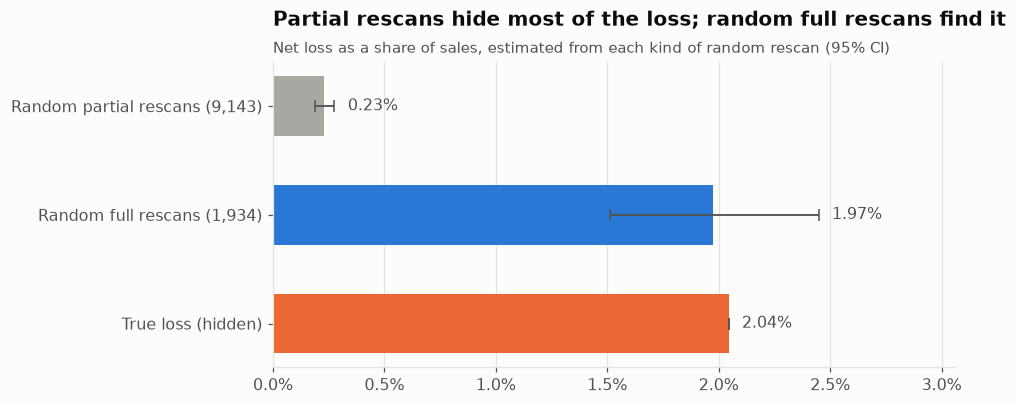

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
m = measure.iloc[::-1]
colors = [GREY, BLUE, ORANGE][::-1]
colors = [ORANGE if 'True' in i else (BLUE if 'full' in i else GREY) for i in m.index]
ax.barh(m.index, m.estimate, color=colors, height=0.55)
ax.errorbar(m.estimate, range(len(m)), xerr=[m.estimate - m.lo, m.hi - m.estimate],
            fmt='none', ecolor=TEXT_2, capsize=4, lw=1.2)
for i, v in enumerate(m.estimate):
    ax.text(m.hi.iloc[i] + 0.0006, i, f'{v:.2%}', va='center', color=TEXT_2)
ax.xaxis.set_major_formatter(pct(1))
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, measure.hi.max() * 1.25)
ax.set_title('Partial rescans hide most of the loss; random full rescans find it')
subtitle(ax, 'Net loss as a share of sales, estimated from each kind of random rescan (95% CI)')
save(fig, '09_what_rescans_measure')
fig

## 6. The baseline to beat: today's random rescans

Four measures, from section 1 of the project outline. "Honest shopper stopped" means a rescanned
session with no deliberate non-scan (it may still contain a genuine mistake, which a rescan
fixes in the shopper's favour or the store's).

In [10]:
r = rescans.merge(truth, on='basket_id')
hours = r.rescan_seconds.sum() / 3600
recovered = (r.found_missing_value - r.found_over_value).sum()
honest_stopped = (r.gt_deliberate_value == 0).sum()
baseline = pd.Series({
    'sessions rescanned': len(r) / len(truth),
    'colleague hours': hours,
    '$ recovered (net)': recovered,
    '$ recovered per colleague hour': recovered / hours,
    'share of total loss recovered': recovered / truth.gt_net_loss.sum(),
    'share of deliberate loss found': (r.found_missing_value * (r.gt_deliberate_value > 0)).sum() / truth.gt_deliberate_value.sum(),
    'rescans that stop an honest shopper': honest_stopped / len(r),
    'honest sessions stopped, share of honest sessions': honest_stopped / (truth.gt_deliberate_value == 0).sum(),
})
baseline.round(4)

sessions rescanned                                      0.1212
colleague hours                                       221.4158
$ recovered (net)                                    2421.9497
$ recovered per colleague hour                         10.9385
share of total loss recovered                           0.0312
share of deliberate loss found                          0.0275
rescans that stop an honest shopper                     0.9560
honest sessions stopped, share of honest sessions       0.1211
dtype: float64

## 7. The signals are realistic, not planted

Models only ever see `sim_obs`. The truth leaves traces there through *mechanisms*, not labels:
shopping time follows the true basket, so a shopper with unscanned items looks slow for what they
scanned, and some deliberate skips are done by scanning then deleting. Each signal on its own
separates deliberate sessions only weakly, as it would in a real store.

In [11]:
from sklearn.metrics import roc_auc_score

obs = q('''
WITH ev AS (
    SELECT basket_id, SUM(CASE WHEN action = 'scan' THEN 1 ELSE -1 END) AS scanned_units,
           COUNT(*) FILTER (WHERE action = 'delete') AS deletes
    FROM sim_obs.scan_events GROUP BY 1
)
SELECT s.basket_id, s.duration_min, COALESCE(ev.scanned_units, 0) AS scanned_units,
       COALESCE(ev.deletes, 0) AS deletes, t.gt_deliberate_value > 0 AS deliberate
FROM sim_obs.sessions s LEFT JOIN ev USING (basket_id) JOIN sim_truth.sessions t USING (basket_id)
''')
n = obs.scanned_units.clip(lower=1)
pd.Series({
    'minutes per scanned unit': roc_auc_score(obs.deliberate, obs.duration_min / n),
    'deletions per scanned unit': roc_auc_score(obs.deliberate, obs.deletes / n),
    'scanned units': roc_auc_score(obs.deliberate, obs.scanned_units),
}, name='AUC for deliberate sessions (0.5 = no signal)').round(3)

minutes per scanned unit      0.550
deletions per scanned unit    0.664
scanned units                 0.526
Name: AUC for deliberate sessions (0.5 = no signal), dtype: float64

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Every published check is matched: errors in ~31% / 65% / 88% of 20 / 50 / 100-unit baskets (ECR: 30 / 60 / 90%); 76% of item errors are non-scans (77%); 55% of non-scanned value is deliberate (46–56%); net loss is 2.0% of sales (0.96–4.68%); 12% rescanned (12%) | The simulated world is consistent with what retailers measure |
| 2 | 14% of members (opportunist, deliberate, adaptive) cause 75% of the loss; genuine mistakes by everyone else are the other 25% | Two problems: catch deliberate skips, and correct honest mistakes without treating people as suspects |
| 3 | High-risk items are 19% of value but 47% of deliberately skipped value (18% of accidental) | Item choice matters: targeted rescans should look there first |
| 4 | Random partial rescans find an error in 3.0% of checks (ECR: 2.88%) and put loss at 0.23% of sales, about a ninth of the truth (2.04%); random full rescans estimate 1.97% (95% CI 1.51–2.45%) | Measure with random full rescans (the random floor); never judge loss from partial checks |
| 5 | Today's random rescans: 12% of sessions, 221 colleague hours, \$10.94 recovered per hour, 3.1% of loss recovered; 96% of rescans stop a shopper who skipped nothing on purpose | The baseline week 8 must beat |
| 6 | Single observable signals carry real but weak information (AUC 0.56–0.66) | Week 5's risk model has to combine many weak signals, as in a real store |

**Limits.** Shopper mix, theft intensity, rescan timings and the concealment of deliberate skips
are assumptions tuned to the published totals, not measured directly. Week 8 reruns the
comparison under lower and higher loss settings.